# Interactive Multilingual Retrieval Fairness Demo

This notebook is a **small live demonstrator** for English, Hindi and Malayalam retrieval using the Belebele test split.

It compares:
- BM25 (keyword retrieval)
- Multilingual E5-small (dense retrieval)
- Multilingual MiniLM (dense retrieval)

It displays the top retrieved passages and whether the known relevant passage appears in the top-k. This is a demo, not the full statistical evaluation. Run the cells from top to bottom.

## 1. Set up the Colab environment



In [2]:
!pip -q install "datasets>=2.19" "sentence-transformers>=3.0,<6" "rank-bm25>=0.2.2" pandas numpy matplotlib ipywidgets

## 2. Load the Belebele data

We use the official English, Hindi and Malayalam test configurations. In the current Hugging Face dataset schema, the passage field is named `flores_passage`, so the loading cell renames it to `passage` for consistent use throughout this notebook. Each row has a question, a passage and four multiple-choice answers. For this retrieval demonstration, passages are the retrieval corpus and the passage attached to the selected question is treated as the relevant passage.


In [3]:
from datasets import load_dataset
import pandas as pd
import numpy as np
import re, time, warnings
from rank_bm25 import BM25Okapi
from sentence_transformers import SentenceTransformer
from IPython.display import display, Markdown
import ipywidgets as widgets

LANG_CONFIG = {
    "English": "eng_Latn",
    "Hindi": "hin_Deva",
    "Malayalam": "mal_Mlym"
}

frames = {}
for name, config in LANG_CONFIG.items():
    df = load_dataset("facebook/belebele", config, split="test").to_pandas().reset_index(drop=True)

    # Current Belebele releases call the passage field "flores_passage".
    # Normalise it so the rest of this notebook uses one consistent name.
    if "passage" not in df.columns and "flores_passage" in df.columns:
        df = df.rename(columns={"flores_passage": "passage"})

    frames[name] = df

required = ["passage", "question"]
for name, df in frames.items():
    missing = [c for c in required if c not in df.columns]
    if missing:
        raise ValueError(
            f"{name} data is missing columns: {missing}. "
            f"Available columns: {list(df.columns)}"
        )

print("Loaded rows:", {name: len(df) for name, df in frames.items()})
print("Normalised columns:", list(frames["English"].columns))


README.md:   0%|          | 0.00/25.5k [00:00<?, ?B/s]

eng_Latn.jsonl:   0%|          | 0.00/836k [00:00<?, ?B/s]

Generating test split:   0%|          | 0/900 [00:00<?, ? examples/s]

hin_Deva.jsonl:   0%|          | 0.00/3.12M [00:00<?, ?B/s]

Generating test split:   0%|          | 0/900 [00:00<?, ? examples/s]

mal_Mlym.jsonl:   0%|          | 0.00/3.83M [00:00<?, ?B/s]

Generating test split:   0%|          | 0/900 [00:00<?, ? examples/s]

Loaded rows: {'English': 900, 'Hindi': 900, 'Malayalam': 900}
Normalised columns: ['link', 'question_number', 'passage', 'question', 'mc_answer1', 'mc_answer2', 'mc_answer3', 'mc_answer4', 'correct_answer_num', 'dialect', 'ds']


## 3. Prepare retrieval corpora

We remove duplicate passages but keep a row-to-passage mapping, so the selected question's passage can be identified as relevant.

In [4]:
def prepare_corpus(df):
    docs, lookup, row_to_doc = [], {}, []
    for passage in df["passage"].fillna("").astype(str):
        if passage not in lookup:
            lookup[passage] = len(docs)
            docs.append(passage)
        row_to_doc.append(lookup[passage])
    return docs, row_to_doc

corpora, row_maps = {}, {}
for lang, df in frames.items():
    corpora[lang], row_maps[lang] = prepare_corpus(df)

print("Unique passages:", {lang: len(docs) for lang, docs in corpora.items()})

Unique passages: {'English': 488, 'Hindi': 488, 'Malayalam': 488}


## 4. Scaled processing with PySpark (`local[*]`)

To show big-data style processing, we run a distributed-style text-processing job (tokenisation + term-frequency counts, the same statistics behind BM25 indexing) using **PySpark in Colab**, i.e. parallel processing across all available CPU cores.

We (1) create a Spark DataFrame from the Belebele passages, (2) inspect partitioning, (3) benchmark Spark vs a single-process Python baseline at increasing dataset sizes, and (4) plot time and throughput.

In [5]:
!pip -q install pyspark

In [6]:
import os, multiprocessing
from pyspark.sql import SparkSession, functions as F

N_CORES = multiprocessing.cpu_count()

spark = (SparkSession.builder
         .master("local[*]")
         .appName("MultilingualRetrievalScaling")
         .config("spark.driver.memory", "4g")
         .config("spark.sql.shuffle.partitions", str(N_CORES * 2))
         .config("spark.ui.showConsoleProgress", "false")
         .getOrCreate())

print("Spark version:", spark.version)
print("CPU cores available:", N_CORES)
print("Default parallelism:", spark.sparkContext.defaultParallelism)

Spark version: 4.0.5
CPU cores available: 2
Default parallelism: 2


In [7]:
# Spark DataFrame of the unique passages for all three languages
base_pdf = pd.DataFrame(
    [(lang, i, doc) for lang, docs in corpora.items() for i, doc in enumerate(docs)],
    columns=["lang", "doc_id", "passage"]
)
base_sdf = spark.createDataFrame(base_pdf)
print("Base passages:", base_sdf.count())
base_sdf.groupBy("lang").count().show()

# Partitioning demonstration: how rows are spread across partitions
for p in [1, 4, N_CORES, N_CORES * 4]:
    part_df = base_sdf.repartition(p)
    sizes = (part_df.withColumn("pid", F.spark_partition_id())
                    .groupBy("pid").count().orderBy("pid")
                    .toPandas()["count"].tolist())
    print(f"repartition({p:>2}) -> {part_df.rdd.getNumPartitions():>2} partitions | rows per partition: {sizes}")

Base passages: 1464
+---------+-----+
|     lang|count|
+---------+-----+
|    Hindi|  488|
|  English|  488|
|Malayalam|  488|
+---------+-----+

repartition( 1) ->  1 partitions | rows per partition: [1464]
repartition( 4) ->  4 partitions | rows per partition: [366, 366, 366, 366]
repartition( 2) ->  2 partitions | rows per partition: [732, 732]
repartition( 8) ->  8 partitions | rows per partition: [182, 182, 184, 184, 184, 184, 182, 182]


In [8]:
import time
from collections import Counter

SCALE_FACTORS = [1, 10, 50, 100, 200]   # multiples of the base corpus
REPEATS = 2                              # timing runs per setting (after one warm-up)
base_rows = list(zip(base_pdf["lang"], base_pdf["passage"]))

def spark_job(sdf):
    # tokenise (whitespace) -> explode -> term frequency per language; count() forces execution
    tokens = (sdf.select("lang", F.explode(F.split(F.lower("passage"), r"\s+")).alias("tok"))
                 .filter(F.col("tok") != ""))
    return tokens.groupBy("lang", "tok").count().count()

def python_job(rows):
    counters = {}
    for lang, text in rows:
        counters.setdefault(lang, Counter()).update(text.lower().split())
    return sum(len(c) for c in counters.values())

results = []
for k in SCALE_FACTORS:
    n_docs = len(base_rows) * k
    # build input once (not timed) so we measure processing only
    sdf = (base_sdf.crossJoin(spark.range(k).withColumnRenamed("id", "rep"))
                   .repartition(N_CORES * 2).cache())
    sdf.count()
    rows = base_rows * k

    spark_job(sdf)  # warm-up
    t_spark = np.mean([(lambda s: (spark_job(sdf), time.perf_counter() - s)[1])(time.perf_counter())
                       for _ in range(REPEATS)])
    t_py = np.mean([(lambda s: (python_job(rows), time.perf_counter() - s)[1])(time.perf_counter())
                    for _ in range(REPEATS)])
    sdf.unpersist()

    results.append({"Docs": n_docs,
                    "Spark time (s)": t_spark, "Python time (s)": t_py,
                    "Spark docs/s": n_docs / t_spark, "Python docs/s": n_docs / t_py,
                    "Speedup (Python/Spark)": t_py / t_spark})
    print(f"{n_docs:>8} docs | Spark {t_spark:6.2f}s | Python {t_py:6.2f}s")

bench = pd.DataFrame(results)
display(bench.round(2))

    1464 docs | Spark   0.98s | Python   0.12s
   14640 docs | Spark   2.60s | Python   1.30s
   73200 docs | Spark   6.45s | Python   1.57s
  146400 docs | Spark   7.36s | Python   3.19s
  292800 docs | Spark  13.88s | Python   7.17s


,Docs,Spark time (s),Python time (s),Spark docs/s,Python docs/s,Speedup (Python/Spark)
0,1464,0.98,0.12,1492.16,12388.62,0.12
1,14640,2.60,1.30,5630.82,11236.41,0.50
2,73200,6.45,1.57,11343.98,46562.55,0.24
3,146400,7.36,3.19,19891.07,45884.87,0.43
4,292800,13.88,7.17,21094.73,40837.25,0.52


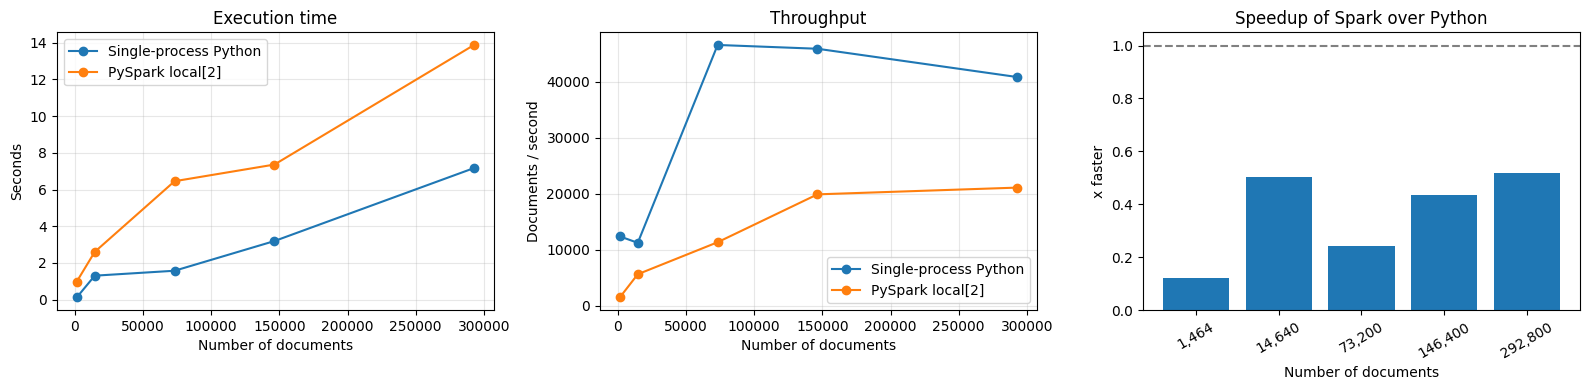

In [9]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 3, figsize=(16, 4))

ax[0].plot(bench["Docs"], bench["Python time (s)"], "o-", label="Single-process Python")
ax[0].plot(bench["Docs"], bench["Spark time (s)"], "o-", label=f"PySpark local[{N_CORES}]")
ax[0].set(title="Execution time", xlabel="Number of documents", ylabel="Seconds")

ax[1].plot(bench["Docs"], bench["Python docs/s"], "o-", label="Single-process Python")
ax[1].plot(bench["Docs"], bench["Spark docs/s"], "o-", label=f"PySpark local[{N_CORES}]")
ax[1].set(title="Throughput", xlabel="Number of documents", ylabel="Documents / second")

ax[2].bar(range(len(bench)), bench["Speedup (Python/Spark)"], tick_label=[f"{d:,}" for d in bench["Docs"]])
ax[2].axhline(1, color="grey", ls="--")
ax[2].set(title="Speedup of Spark over Python", xlabel="Number of documents", ylabel="x faster")
ax[2].tick_params(axis="x", rotation=30)

for a in ax[:2]:
    a.legend(); a.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Load retrieval models

BM25 is lightweight. Dense models download their weights the first time. E5 uses the recommended `query:` and `passage:` prefixes.

In [10]:
from sentence_transformers import SentenceTransformer

e5_model = SentenceTransformer("intfloat/multilingual-e5-small")
minilm_model = SentenceTransformer("sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2")
print("Both embedding models are ready.")

modules.json:   0%|          | 0.00/387 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/498k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/655 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  471MB            

model.safetensors: downloading bytes:           |  0.00B            

... (18 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Both embedding models are ready.


## 6. Interactive retrieval demo

Choose a language, a question from that language's test set, and a retrieval model. We can edit the query before searching. The relevant passage is determined by the selected dataset row.

In [11]:
def tokenize(text):
    return re.findall(r"\w+", str(text).lower(), flags=re.UNICODE)

def retrieve(query, docs, method):
    start = time.time()
    if method == "BM25":
        model = BM25Okapi([tokenize(x) for x in docs])
        scores = model.get_scores(tokenize(query))
    else:
        model = e5_model if method == "Multilingual E5-small" else minilm_model
        if method == "Multilingual E5-small":
            q = "query: " + query
            passages = ["passage: " + x for x in docs]
        else:
            q = query
            passages = docs
        qv = model.encode([q], convert_to_numpy=True, normalize_embeddings=True)
        dv = model.encode(passages, batch_size=64, convert_to_numpy=True,
                          normalize_embeddings=True, show_progress_bar=False)
        scores = (qv @ dv.T)[0]
    elapsed = time.time() - start
    ranking = np.argsort(-np.asarray(scores))
    return ranking, elapsed

lang_widget = widgets.Dropdown(options=list(LANG_CONFIG.keys()), value="Malayalam", description="Language:")
index_widget = widgets.IntSlider(value=0, min=0, max=len(frames["Malayalam"])-1, step=1, description="Example:")
method_widget = widgets.Dropdown(
    options=["BM25", "Multilingual E5-small", "Multilingual MiniLM"],
    value="Multilingual E5-small", description="Model:"
)
query_widget = widgets.Textarea(
    value=frames["Malayalam"].iloc[0]["question"],
    description="Query:", layout=widgets.Layout(width="100%", height="90px")
)
run_button = widgets.Button(description="Retrieve top 5", button_style="success", icon="search")
output = widgets.Output()

def update_query(*args):
    lang = lang_widget.value
    idx = min(index_widget.value, len(frames[lang])-1)
    query_widget.value = str(frames[lang].iloc[idx]["question"])

lang_widget.observe(update_query, names="value")
index_widget.observe(update_query, names="value")

def run_demo(_):
    with output:
        output.clear_output()
        lang, idx, method = lang_widget.value, index_widget.value, method_widget.value
        df = frames[lang]
        idx = min(idx, len(df)-1)
        docs = corpora[lang]
        gold_doc = row_maps[lang][idx]
        query = query_widget.value.strip()
        if not query:
            print("Please enter a query.")
            return
        ranking, elapsed = retrieve(query, docs, method)
        topk = ranking[:5]
        hit_rank = next((r for r, doc_id in enumerate(ranking, 1) if doc_id == gold_doc), None)
        display(Markdown(f"### {lang} | {method}"))
        print("Query:", query)
        print(f"Retrieval time: {elapsed:.2f} seconds")
        print("Relevant passage rank:", hit_rank if hit_rank is not None else "Not found")
        print("\nTop retrieved passages:")
        for rank, doc_id in enumerate(topk, 1):
            marker = "  <-- RELEVANT PASSAGE" if doc_id == gold_doc else ""
            snippet = docs[int(doc_id)].replace("\n", " ")
            print(f"\n{rank}. {snippet[:700]}{marker}")
        print("\nDemo note: relevance is based on the passage linked to the selected Belebele question.")

run_button.on_click(run_demo)
display(widgets.VBox([
    lang_widget, index_widget, method_widget, query_widget, run_button, output
]))

## 7. Compare a few examples across languages

This cell evaluates the first N questions using the selected model and reports Recall@1, Recall@5, Recall@10 and MRR.

In [13]:

def evaluate_language(lang, method="Multilingual E5-small", n=30):
    df = frames[lang].head(n)
    docs = corpora[lang]
    golds = row_maps[lang][:len(df)]
    reciprocal_ranks, hits1, hits5, hits10 = [], [], [], []

    for i, row in df.iterrows():
        ranking, _ = retrieve(str(row["question"]), docs, method)
        gold = golds[i]
        positions = np.where(ranking == gold)[0]
        rank = int(positions[0]) + 1 if len(positions) else None

        reciprocal_ranks.append(1/rank if rank else 0.0)
        hits1.append(rank is not None and rank <= 1)
        hits5.append(rank is not None and rank <= 5)
        hits10.append(rank is not None and rank <= 10)

    return {
        "Language": lang, "Model": method, "Queries": len(df),
        "Recall@1": np.mean(hits1), "Recall@5": np.mean(hits5),
        "Recall@10": np.mean(hits10), "MRR": np.mean(reciprocal_ranks)
    }


# Evaluate all three retrieval methods
N_DEMO = 20

methods = [
    "BM25",
    "Multilingual E5-small",
    "Multilingual MiniLM"
]

summary = pd.DataFrame([
    evaluate_language(lang, method=method, n=N_DEMO)
    for method in methods
    for lang in ["English", "Hindi", "Malayalam"]
])

display(summary.round(3))


,Language,Model,Queries,Recall@1,Recall@5,Recall@10,MRR
0,English,BM25,20,0.85,1.00,1.00,0.904
1,Hindi,BM25,20,0.40,0.60,0.65,0.500
2,Malayalam,BM25,20,0.45,0.75,0.90,0.563
3,English,Multilingual E5-small,20,1.00,1.00,1.00,1.000
4,Hindi,Multilingual E5-small,20,0.85,0.95,0.95,0.888
5,Malayalam,Multilingual E5-small,20,0.85,0.90,1.00,0.886
6,English,Multilingual MiniLM,20,0.80,0.95,1.00,0.859
7,Hindi,Multilingual MiniLM,20,0.60,0.75,0.75,0.662
8,Malayalam,Multilingual MiniLM,20,0.00,0.05,0.15,0.037


## 8. Important interpretation and limitations

- This is a small demonstration subset, not the final benchmark result.
- The retrieval relevance signal here is the passage associated with the selected question.
- This does not evaluate answer generation or human-perceived answer quality.
-  Small data can run slower in Spark because of start-up and shuffle overhead; the benefit appears as data grows. The benchmark replicates the corpus to simulate larger sizes.